## الاسماء :

### رائد  عفانة ,عمر  حرب  

## 1. Set environment

### Load libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings #مكتبة warnings :مفيدة في حالات مثل تحذيرات معينة تظهر بشكل متكرر وترغب في إيقاف ظهورها أو التحكم فيها بطريقة معينة

warnings.filterwarnings('ignore')
pd.options.display.max_columns = None

In [2]:
df = pd.read_csv("ds_salaries.csv")
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


### Preliminary EDA

In [3]:
df.shape   #Dimensions of dataset  

(3755, 11)

In [4]:
df.describe()    #Summary of dataset  

,work_year,salary,salary_in_usd,remote_ratio
count,3755.000000,3.755000e+03,3755.000000,3755.000000
mean,2022.373635,1.906956e+05,137570.389880,46.271638
std,0.691448,6.716765e+05,63055.625278,48.589050
min,2020.000000,6.000000e+03,5132.000000,0.000000
25%,2022.000000,1.000000e+05,95000.000000,0.000000
50%,2022.000000,1.380000e+05,135000.000000,0.000000
75%,2023.000000,1.800000e+05,175000.000000,100.000000
max,2023.000000,3.040000e+07,450000.000000,100.000000


In [5]:
df.dtypes #Datatypes

work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object

## 2. Data processing

### Rename categorical column values for better understanding

In [6]:
df['experience_level'] = df['experience_level'].replace({'SE':'Senior', 'MI':'Mid-level', 'EN':'Entry-level','EX':'Executive-level'})
df['employment_type'] = df['employment_type'].replace({'FT':'Full-time', 'CT':'Contractual','PT':'Part-time', 'FL':'Freelancer'})
df['remote_ratio'] = df['remote_ratio'].replace({100: 'On-site', 0:'Remote', 50:'Hybrid'})

### Check for duplicates

In [7]:
duplicate_rows = df[df.duplicated()]
duplicate_rows.shape

#keep only the first row of the duplicated rows
df = df.drop_duplicates(keep='last')
df

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,Senior,Full-time,Principal Data Scientist,80000,EUR,85847,ES,On-site,ES,L
1,2023,Mid-level,Contractual,ML Engineer,30000,USD,30000,US,On-site,US,S
2,2023,Mid-level,Contractual,ML Engineer,25500,USD,25500,US,On-site,US,S
3,2023,Senior,Full-time,Data Scientist,175000,USD,175000,CA,On-site,CA,M
4,2023,Senior,Full-time,Data Scientist,120000,USD,120000,CA,On-site,CA,M
...,...,...,...,...,...,...,...,...,...,...,...
3750,2020,Senior,Full-time,Data Scientist,412000,USD,412000,US,On-site,US,L
3751,2021,Mid-level,Full-time,Principal Data Scientist,151000,USD,151000,US,On-site,US,L
3752,2020,Entry-level,Full-time,Data Scientist,105000,USD,105000,US,On-site,US,S
3753,2020,Entry-level,Contractual,Business Data Analyst,100000,USD,100000,US,On-site,US,L


### Drop unnecessary columns

In [8]:
df = df.drop(['salary_currency', 'salary'], axis=1)
df

,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,Senior,Full-time,Principal Data Scientist,85847,ES,On-site,ES,L
1,2023,Mid-level,Contractual,ML Engineer,30000,US,On-site,US,S
2,2023,Mid-level,Contractual,ML Engineer,25500,US,On-site,US,S
3,2023,Senior,Full-time,Data Scientist,175000,CA,On-site,CA,M
4,2023,Senior,Full-time,Data Scientist,120000,CA,On-site,CA,M
...,...,...,...,...,...,...,...,...,...
3750,2020,Senior,Full-time,Data Scientist,412000,US,On-site,US,L
3751,2021,Mid-level,Full-time,Principal Data Scientist,151000,US,On-site,US,L
3752,2020,Entry-level,Full-time,Data Scientist,105000,US,On-site,US,S
3753,2020,Entry-level,Contractual,Business Data Analyst,100000,US,On-site,US,L


### Check for missing data

In [9]:
df.isnull().sum()

work_year             0
experience_level      0
employment_type       0
job_title             0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

# informathion for Data

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2584 entries, 0 to 3754
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           2584 non-null   int64 
 1   experience_level    2584 non-null   object
 2   employment_type     2584 non-null   object
 3   job_title           2584 non-null   object
 4   salary_in_usd       2584 non-null   int64 
 5   employee_residence  2584 non-null   object
 6   remote_ratio        2584 non-null   object
 7   company_location    2584 non-null   object
 8   company_size        2584 non-null   object
dtypes: int64(2), object(7)
memory usage: 201.9+ KB


## 3. Visualization

### Top 10 : Job titles and associated average salary

In [11]:
top_salary =  df.groupby('job_title').agg({'salary_in_usd':'mean'}).round(2).sort_values('salary_in_usd', ascending=False).head(10)
top_salary.head(10)

,salary_in_usd
job_title,
Data Science Tech Lead,375000.00
Cloud Data Architect,250000.00
Data Lead,212500.00
Data Analytics Lead,211254.50
Principal Data Scientist,198171.12
Director of Data Science,195140.73
Principal Data Engineer,192500.00
Machine Learning Software Engineer,192420.00
Applied Scientist,190342.58


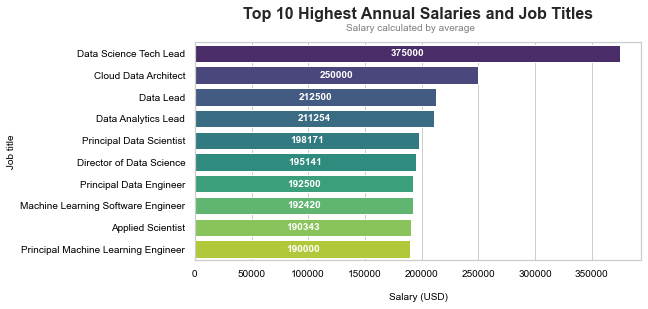

In [12]:
plt.figure(figsize=(8,4))

sns.set(style="whitegrid")
ax= sns.barplot(y = top_salary.index, x ='salary_in_usd', 
            data = top_salary,           
            palette = "viridis")  
            
plt.title('Top 10 Highest Annual Salaries and Job Titles\n', fontsize=16, fontweight="bold", loc="center")
plt.suptitle("\nSalary calculated by average\n", fontsize = 10, color="gray")
plt.xlabel('\nSalary (USD)', color="black", fontsize=10)
plt.ylabel('Job title', color="black", fontsize=10)
plt.xticks(fontsize=10, color="black")
plt.yticks(fontsize=10, color="black")


for i in ax.containers:
    ax.bar_label(i, size=10, label_type = "center", color="white", fontweight="bold")

plt.show() #not needed in Jupyter environment but this opens the plot in another window in other environments

(array([-100000.,       0.,  100000.,  200000.,  300000.,  400000.,
         500000.]),
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

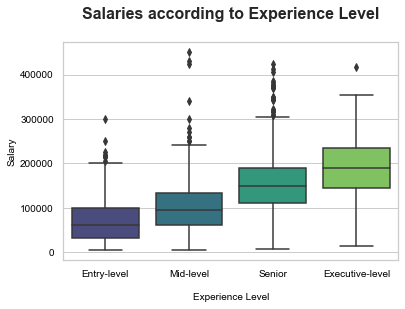

In [13]:
plt.figure(figsize=(6,4))

median_salary = df.groupby('experience_level')['salary_in_usd'].median().reset_index().sort_values('salary_in_usd')

sns.boxplot(data=df, x='experience_level', y='salary_in_usd', 
            order=median_salary['experience_level'], 
            palette="viridis")

plt.title("Salaries according to Experience Level\n", fontsize=16, fontweight="bold", loc="center")
plt.xlabel("\nExperience Level", color="black", fontsize=10)
plt.ylabel("Salary", color="black", fontsize=10)
plt.xticks(fontsize=10, color="black")
plt.yticks(fontsize=10, color="black")  

In [14]:
df.work_year.value_counts()

2023    1156
2022    1125
2021     228
2020      75
Name: work_year, dtype: int64

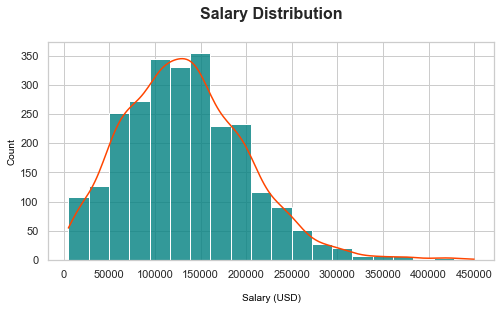

In [23]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,4))

ax = sns.histplot(df['salary_in_usd'], alpha=0.8, color = "teal", bins=20,
             kde = True)

plt.xticks(range(0,500000,50000));
plt.title("Salary Distribution\n", fontsize=16, fontweight = "bold")
plt.xlabel('\nSalary (USD)', color="black",fontsize=10)
plt.ylabel('Count', color = "black", fontsize=10)
ax.lines[0].set_color('orangered') #change color of kde line


### Does job type influence salary?

In [16]:
job_type = df.groupby('employment_type').agg({'salary_in_usd':'mean'}).round(0).sort_values('salary_in_usd', ascending=False)

job_type

,salary_in_usd
employment_type,
Full-time,134435.0
Contractual,113447.0
Freelancer,51808.0
Part-time,39534.0


In [24]:
import plotly.express as px

fig = px.scatter(job_type, x="salary_in_usd", y=None,
                 size="salary_in_usd", color=job_type.index,
                 size_max=60)

fig.update_layout(yaxis=dict(title=''), xaxis=dict(title='\nAvg. Annual Salary'), title={'text':'Job Type and Average Salary', 'font':{'size':22}})
fig.update_xaxes(range=[5000, 150000], dtick=10000)
fig.update_layout(width=800, height=400)

fig.show()

### Salary range according to company size


In [18]:
print("Salary according to company size \n")
round(df.groupby('company_size').agg({'salary_in_usd':'mean'}),2)

Salary according to company size 



,salary_in_usd
company_size,
L,113202.24
M,141474.51
S,78364.28


In [19]:
print("Minimum salary: $", df.salary_in_usd.min(),"\nAverage salary: $", round(df.salary_in_usd.mean(),2), "\nMaximum salary: $", df.salary_in_usd.max()) 

Minimum salary: $ 5132 
Average salary: $ 133409.28 
Maximum salary: $ 450000


### Which work mode is more prevalent: on-site, remote, or hybrid?

Text(0.5, 1.0, 'Work Mode\n')

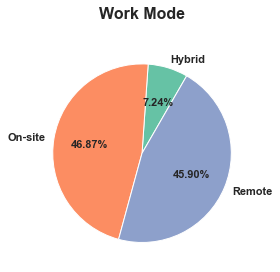

In [20]:
plt.figure(figsize=(4,6))
colors = sns.color_palette('Set2')[0:3]

values = df.groupby('remote_ratio').size()
labels = values.index

plt.pie(values, labels=labels, autopct='%1.2f%%', 
             startangle=60, textprops={'fontsize': 11, 'fontweight':"bold"},
             colors = colors)
plt.title("Work Mode\n", fontsize=16, fontweight="bold")


### Countries stats

In [21]:
df_pivot = df.groupby(['company_location', 'remote_ratio']).size().reset_index(name="count")
df_pivot = df_pivot.pivot_table(index='company_location', columns='remote_ratio', values='count', fill_value=0)
df_pivot.sort_values('Remote', ascending=False).head(10)

remote_ratio,Hybrid,On-site,Remote
company_location,,,
US,39,917,973
GB,17,55,83
CA,12,44,27
ES,5,21,18
DE,14,25,16
IN,20,29,8
PT,3,4,7
IE,0,3,4
NL,3,6,4


### end